# 🎲 Incertitude et sensibilité de la simulation 2026-2027

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie incertitude : Loan

## Pourquoi ce notebook ?
`SIMULATION_2026.ipynb` (Maxime) donne par exemple **25,2 % de titre à Arsenal**, avec une marge de ± 0,85 point. Mais cette marge ne mesure qu'une chose : le **hasard de la simulation** (10 000 saisons, pas une infinité). Elle fait comme si les coefficients du modèle étaient **connus exactement**.

Or ces coefficients sont **estimés** sur 1 871 matchs : ils ont eux-mêmes une marge d'erreur (leurs intervalles de confiance dans `MODEL_POISSON`). Ce notebook répond à deux questions :
1. **Intervalles :** si on tient compte de l'incertitude sur les coefficients, quelle est la vraie fourchette des probabilités de titre ?
2. **Sensibilité :** le classement des favoris change-t-il si on modifie l'avantage du terrain, le poids de l'Elo, celui des forces d'attaque/défense ou celui de la valeur des joueurs récents ?

*Mise à jour du 21 octobre 2026 : tout le notebook utilise le modèle v3 de `MODEL_POISSON` (6 coefficients).*

## Règles
- **On ne modifie ni le modèle ni la simulation.** Le moteur de Maxime est **lu directement** dans `SIMULATION_2026.ipynb` et exécuté tel quel. On vérifie qu'on retrouve exactement ses chiffres avant de faire quoi que ce soit.
- **Aucune donnée nouvelle**, et des graines fixes : les résultats sont reproductibles.

## Plan
1. Charger le moteur de Maxime et retrouver ses chiffres
2. L'incertitude des coefficients du modèle
3. Intervalles sur les probabilités de titre
4. Analyse de sensibilité : terrain, Elo, forces et valeur des joueurs
5. Export
6. Conclusion

In [1]:
from pathlib import Path
from collections import Counter
from math import factorial
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
import statsmodels.api as sm

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, GRIS, ENCRE = '#2a78d6', '#eb6834', '#b5b3ad', '#52514e'
GRAINE = 2026                 # même graine que SIMULATION_2026
N_TIRAGES = 100               # jeux de coefficients tirés au hasard
N_SAISONS_PAR_TIRAGE = 2_000  # saisons simulées pour chaque jeu de coefficients
N_SENSIBILITE = 10_000        # saisons par scénario de sensibilité
COEFS = ['intercept', 'coef_ecart_100', 'coef_terrain', 'coef_force_ad', 'coef_valeur_recente', 'coef_nouveau_format']

# Le moteur de Maxime : on exécute ses cellules de définitions, sans les recopier ni les modifier
source = json.loads(Path('SIMULATION_2026.ipynb').read_text(encoding='utf-8'))
fonctions = ['def buts_attendus(', 'def preparer_calendrier(', 'def actualiser_elo(', 'def classer_ligue(', 'def campagne_simulation(']
cellules = [''.join(c['source']) for c in source['cells'] if c['cell_type'] == 'code'
            and any(f in ''.join(c['source']) for f in fonctions)]
assert len(cellules) == len(fonctions), "Le notebook de Maxime a changé : vérifier les cellules chargées"
for c in cellules:
    exec(c)
assert all(callable(globals()[n]) for n in ['simuler_saison', 'campagne_simulation', 'preparer_calendrier', 'tirer_score'])

# Les mêmes entrées que SIMULATION_2026
p = joblib.load('../output/modele_scores.joblib')           # notre fichier, produit par MODEL_POISSON
calendrier = pd.read_csv('../output/calendrier_2026.csv', parse_dates=['date'], encoding='utf-8-sig')
elos = pd.read_csv('../output/elo_participants_2026.csv', encoding='utf-8-sig')
clubs = calendrier[['club_id', 'nom_uefa']].drop_duplicates().sort_values('club_id').reset_index(drop=True)
elo_initial = clubs['club_id'].map(elos.set_index('club_id')['elo_complet']).to_numpy(float)
# Forces d'attaque/défense et valeur des joueurs récents (v2_forces), dans l'ordre de clubs, comme chez Maxime
forces = pd.read_csv('../output/forces_participants_2026.csv', encoding='utf-8-sig').set_index('club_id').loc[clubs['club_id']]
forces_initiales = np.vstack([forces['attaque'], forces['defense'], np.log(forces['valeur_recente_eur'])]).astype(float)
cal_2026 = preparer_calendrier(calendrier.loc[calendrier['lieu'].eq('domicile')], clubs, forces_initiales)
assert len(clubs) == 36 and np.isfinite(elo_initial).all()
print(f"Moteur chargé : {len(cellules)} cellules de SIMULATION_2026 | {len(cal_2026['affiches'])} matchs | 36 clubs")
print("Coefficients du modèle :", {k: round(p[k], 4) for k in COEFS})

Moteur chargé : 5 cellules de SIMULATION_2026 | 144 matchs | 36 clubs
Coefficients du modèle : {'intercept': 0.346, 'coef_ecart_100': 0.0962, 'coef_terrain': 0.1293, 'coef_force_ad': 0.4406, 'coef_valeur_recente': 0.0531, 'coef_nouveau_format': 0.1194}


## 1. Retrouver les chiffres de Maxime

**Pourquoi :** si notre copie du moteur ne donnait pas exactement les mêmes résultats, tout ce qui suit serait faux. On relance donc sa simulation de référence (10 000 saisons, graine 2026) et on compare :
- aux chiffres publiés par Maxime dans `README_SIMULATION.md` (Arsenal 25,24 %, Bayern 14,87 %, Man City 13,90 %, Barcelone 12,49 %), toujours disponibles dans le dépôt ;
- et, s'il existe, à son fichier complet `output/resultats_simulation_2026.csv`, pour les 36 clubs.

In [2]:
debut = time.perf_counter()
reference = campagne_simulation(cal_2026, clubs, elo_initial, p, 10_000, np.random.default_rng(GRAINE), progression=False)['resultats']
pct_ref = (100 * reference.set_index('nom_uefa')['p_titre']).round(2)

# 1. Les chiffres publiés dans README_SIMULATION.md
publies = {'Arsenal': 25.24, 'Bayern München': 14.87, 'Man City': 13.90, 'FC Barcelona': 12.49}
assert all(pct_ref[club] == valeur for club, valeur in publies.items()), "On ne retrouve pas les chiffres publiés par Maxime"

# 2. Son fichier complet, s'il a été régénéré en local
chemin_maxime = Path('../output/resultats_simulation_2026.csv')
if chemin_maxime.is_file():
    ref_maxime = pd.read_csv(chemin_maxime, encoding='utf-8-sig')
    comparaison = reference[['club_id', 'p_titre']].merge(ref_maxime[['club_id', 'p_titre']], on='club_id', suffixes=('', '_maxime'))
    assert len(comparaison) == 36 and np.allclose(comparaison['p_titre'], comparaison['p_titre_maxime'], atol=1e-12)
    print("Les 36 probabilités de titre de resultats_simulation_2026.csv sont retrouvées à l'identique.")
print(f"Chiffres publiés par Maxime retrouvés ({time.perf_counter() - debut:.0f} s) :")
print(pct_ref.sort_values(ascending=False).head(5).to_string())

Les 36 probabilités de titre de resultats_simulation_2026.csv sont retrouvées à l'identique.
Chiffres publiés par Maxime retrouvés (10 s) :
nom_uefa
Arsenal           25.24
Bayern München    14.87
Man City          13.90
FC Barcelona      12.49
Real Madrid        7.69


**Lecture :** notre copie du moteur retrouve **exactement** la simulation de Maxime : Arsenal **25,24 %**, Bayern **14,87 %**, Man City **13,90 %**, Barcelone **12,49 %**, et les 36 probabilités de son fichier à l'identique. Tout ce qui suit repose donc sur le même moteur, les mêmes entrées et la même graine. Seuls les coefficients changent.

## 2. L'incertitude des coefficients du modèle

Le modèle a 6 coefficients (constante, Elo, terrain, forces d'attaque/défense, valeur des joueurs récents, nouveau format). Ils sont **estimés**, donc incertains. statsmodels donne leur **matrice de covariance** : la taille de l'incertitude de chacun, et la façon dont ils varient ensemble (si la constante est un peu plus haute, le format est souvent un peu plus bas, par exemple).

**La méthode :** on réentraîne exactement le modèle final de `MODEL_POISSON` (mêmes données, mêmes variables) avec statsmodels, et on vérifie qu'on retrouve les coefficients du fichier `modele_scores.joblib`. Puis on tire au hasard **100 jeux de coefficients** dans une loi normale centrée sur les coefficients estimés, avec cette covariance. Chaque jeu est un « modèle plausible » compte tenu des données.

In [3]:
g = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig')
g = g.merge(pd.read_csv('../output/forces_par_match.csv', encoding='utf-8-sig'), on='game_id', how='left', validate='one_to_one')
assert g[['force_ad_dom', 'force_ad_ext', 'ecart_valeur_recente']].notna().all().all()
domicile = (~g['neutre'].astype(bool)).astype(int).to_numpy()
ecart = g['ecart_elo_complet'].to_numpy() / 100
nouveau = (g['season'] >= 2024).astype(int).to_numpy()
lignes = pd.DataFrame({                                      # 2 lignes par match, comme dans MODEL_POISSON
    'buts': np.r_[g['dom_j_buts_pour'], g['ext_j_buts_pour']],
    'ecart_100': np.r_[ecart, -ecart], 'terrain': np.r_[domicile, -domicile],
    'force_ad': np.r_[g['force_ad_dom'], g['force_ad_ext']],                      # attaque de l'équipe + défense adverse
    'valeur_recente': np.r_[g['ecart_valeur_recente'], -g['ecart_valeur_recente']],
    'nouveau_format': np.r_[nouveau, nouveau]})
variables = ['ecart_100', 'terrain', 'force_ad', 'valeur_recente', 'nouveau_format']   # même ordre que COEFS
ajust = sm.GLM(lignes['buts'], sm.add_constant(lignes[variables]), family=sm.families.Poisson()).fit()

estimes = ajust.params.to_numpy()
covariance = ajust.cov_params().to_numpy()
assert np.allclose(estimes, [p[k] for k in COEFS], atol=1e-4), "Ce n'est pas le modèle de modele_scores.joblib"

rng_coefs = np.random.default_rng(GRAINE)
tirages_coefs = rng_coefs.multivariate_normal(estimes, covariance, size=N_TIRAGES)
tableau_coefs = pd.DataFrame({
    'estimé': estimes, 'écart-type': np.sqrt(np.diag(covariance)),
    'IC 95 % bas': ajust.conf_int()[0].to_numpy(), 'IC 95 % haut': ajust.conf_int()[1].to_numpy(),
    'tirages : min': tirages_coefs.min(axis=0), 'tirages : max': tirages_coefs.max(axis=0)}, index=COEFS)
print(f"Modèle de modele_scores.joblib retrouvé. {N_TIRAGES} jeux de coefficients tirés.\n")
print(tableau_coefs.round(4).to_string())

Modèle de modele_scores.joblib retrouvé. 100 jeux de coefficients tirés.

                     estimé  écart-type  IC 95 % bas  IC 95 % haut  tirages : min  tirages : max
intercept            0.3460      0.0163       0.3141        0.3780         0.3064         0.3898
coef_ecart_100       0.0962      0.0143       0.0681        0.1242         0.0521         0.1456
coef_terrain         0.1293      0.0134       0.1031        0.1555         0.1045         0.1544
coef_force_ad        0.4406      0.0598       0.3233        0.5579         0.2857         0.5830
coef_valeur_recente  0.0531      0.0120       0.0297        0.0766         0.0148         0.0837
coef_nouveau_format  0.1194      0.0318       0.0570        0.1818         0.0438         0.2254


**Lecture :**
- **On retrouve le modèle de `modele_scores.joblib`** : constante 0,346, Elo 0,096, terrain 0,129, forces 0,441, valeur des joueurs récents 0,053, nouveau format 0,119.
- **Le coefficient le plus incertain reste celui du nouveau format** : écart-type de 0,032, soit **27 %** de sa valeur (intervalle de 0,057 à 0,182). Vient ensuite la valeur des joueurs récents (**23 %**). C'est cohérent avec l'audit : le nouveau format n'a été observé que sur 2 saisons.
- **L'Elo est moins précis qu'avec l'ancien modèle** : 15 % de sa valeur, contre 3,5 % avant. Ce n'est pas un défaut : l'Elo, les forces et la valeur des joueurs mesurent en partie la même chose (le niveau du club), donc le modèle a plus de mal à attribuer le mérite à chacun.
- **Les 100 tirages couvrent bien ces intervalles** : par exemple, le coefficient du format va de 0,044 à 0,225 selon le tirage.

## 3. Intervalles sur les probabilités de titre

**La méthode :** pour chacun des 100 jeux de coefficients, on simule **2 000 saisons** avec le moteur de Maxime, soit **200 000 saisons** en tout, réparties sur les cœurs du processeur. On obtient 100 probabilités de titre par club. Leur dispersion mélange deux sources d'incertitude :
- le **hasard de nos blocs de simulation** (2 000 saisons par jeu de coefficients) ;
- l'**incertitude des coefficients**, celle qui nous intéresse.

**On sépare les deux.** La variance due au hasard d'un bloc se calcule exactement : p × (1 − p) / 2 000. On la retire de la variance observée, et ce qui reste est la part due aux coefficients.

**Pourquoi ne pas prendre directement la fourchette des 100 valeurs ?** Parce qu'elle contiendrait le hasard de *nos* blocs de 2 000 saisons, plus bruités que la simulation de Maxime (10 000 saisons) : elle surestimerait l'incertitude. La bonne marge, pour la probabilité publiée par Maxime, additionne les deux variances :

$$\text{marge totale} = 1{,}96 \times \sqrt{\underbrace{\tfrac{p(1-p)}{10\,000}}_{\text{hasard de la simulation}} + \underbrace{\sigma^2_{\text{coefficients}}}_{\text{incertitude du modèle}}}$$

In [4]:
def simuler_avec(coefs, n, graine):
    # Une campagne de n saisons avec d'autres coefficients ; chaque bloc a sa propre graine fixe
    p_k = dict(p, **coefs)
    r = campagne_simulation(cal_2026, clubs, elo_initial, p_k, n, np.random.default_rng(graine), progression=False)['resultats']
    return r['p_titre'].to_numpy(), r['p_quarts'].to_numpy()

# Les 100 jeux de coefficients sont indépendants : on les répartit sur les cœurs du processeur.
# Graine [GRAINE, k] pour le jeu k : le résultat ne dépend pas du nombre de cœurs.
debut = time.perf_counter()
blocs = Parallel(n_jobs=-1)(delayed(simuler_avec)(dict(zip(COEFS, t)), N_SAISONS_PAR_TIRAGE, [GRAINE, k])
                            for k, t in enumerate(tirages_coefs))
probas_titre = np.array([b[0] for b in blocs])
probas_quarts = np.array([b[1] for b in blocs])

assert np.allclose(probas_titre.sum(axis=1), 1) and np.allclose(probas_quarts.sum(axis=1), 8)

def marges(probas, p_reference, n_reference=10_000):
    # Marges à 95 % (en points de %) : hasard de la simulation de référence, coefficients, et total
    var_blocs = (probas * (1 - probas)).mean(axis=0) / N_SAISONS_PAR_TIRAGE     # hasard de nos blocs
    var_coefs = np.maximum(probas.var(axis=0, ddof=1) - var_blocs, 0)            # ce qui reste : les coefficients
    var_simulation = p_reference * (1 - p_reference) / n_reference              # hasard de la simulation de Maxime
    return (100 * 1.96 * np.sqrt(var_simulation), 100 * 1.96 * np.sqrt(var_coefs),
            100 * 1.96 * np.sqrt(var_simulation + var_coefs))

ref = reference.set_index('club_id').loc[clubs['club_id']]
incertitude = clubs[['club_id', 'nom_uefa']].assign(elo_initial=elo_initial)
for tour, probas in [('titre', probas_titre), ('quarts', probas_quarts)]:
    p_ref = ref[f'p_{tour}'].to_numpy()
    m_sim, m_coefs, m_totale = marges(probas, p_ref)
    incertitude[f'pct_{tour}_reference'] = 100 * p_ref
    incertitude[f'pct_{tour}_moyen_coefs_incertains'] = 100 * probas.mean(axis=0)
    incertitude[f'marge_{tour}_simulation_pts'] = m_sim
    incertitude[f'marge_{tour}_coefficients_pts'] = m_coefs
    incertitude[f'marge_{tour}_totale_pts'] = m_totale
    incertitude[f'pct_{tour}_ic95_bas'] = np.maximum(100 * p_ref - m_totale, 0)
    incertitude[f'pct_{tour}_ic95_haut'] = np.minimum(100 * p_ref + m_totale, 100)
incertitude = incertitude.sort_values('pct_titre_reference', ascending=False).reset_index(drop=True)

print(f"{N_TIRAGES * N_SAISONS_PAR_TIRAGE:,} saisons simulées en {time.perf_counter() - debut:.0f} s\n")
print(incertitude.head(10)[['nom_uefa', 'pct_titre_reference', 'pct_titre_moyen_coefs_incertains', 'marge_titre_simulation_pts',
                            'marge_titre_coefficients_pts', 'marge_titre_totale_pts', 'pct_titre_ic95_bas', 'pct_titre_ic95_haut']]
      .round(2).to_string(index=False))
print("\nQuarts de finale :")
print(incertitude.head(10)[['nom_uefa', 'pct_quarts_reference', 'marge_quarts_simulation_pts', 'marge_quarts_coefficients_pts',
                            'pct_quarts_ic95_bas', 'pct_quarts_ic95_haut']].round(2).to_string(index=False))

200,000 saisons simulées en 21 s

      nom_uefa  pct_titre_reference  pct_titre_moyen_coefs_incertains  marge_titre_simulation_pts  marge_titre_coefficients_pts  marge_titre_totale_pts  pct_titre_ic95_bas  pct_titre_ic95_haut
       Arsenal                25.24                             24.69                        0.85                          2.04                    2.21               23.03                27.45
Bayern München                14.87                             14.78                        0.70                          0.30                    0.76               14.11                15.63
      Man City                13.90                             14.47                        0.68                          1.05                    1.25               12.65                15.15
  FC Barcelona                12.49                             12.02                        0.65                          0.85                    1.07               11.42                13.56
 

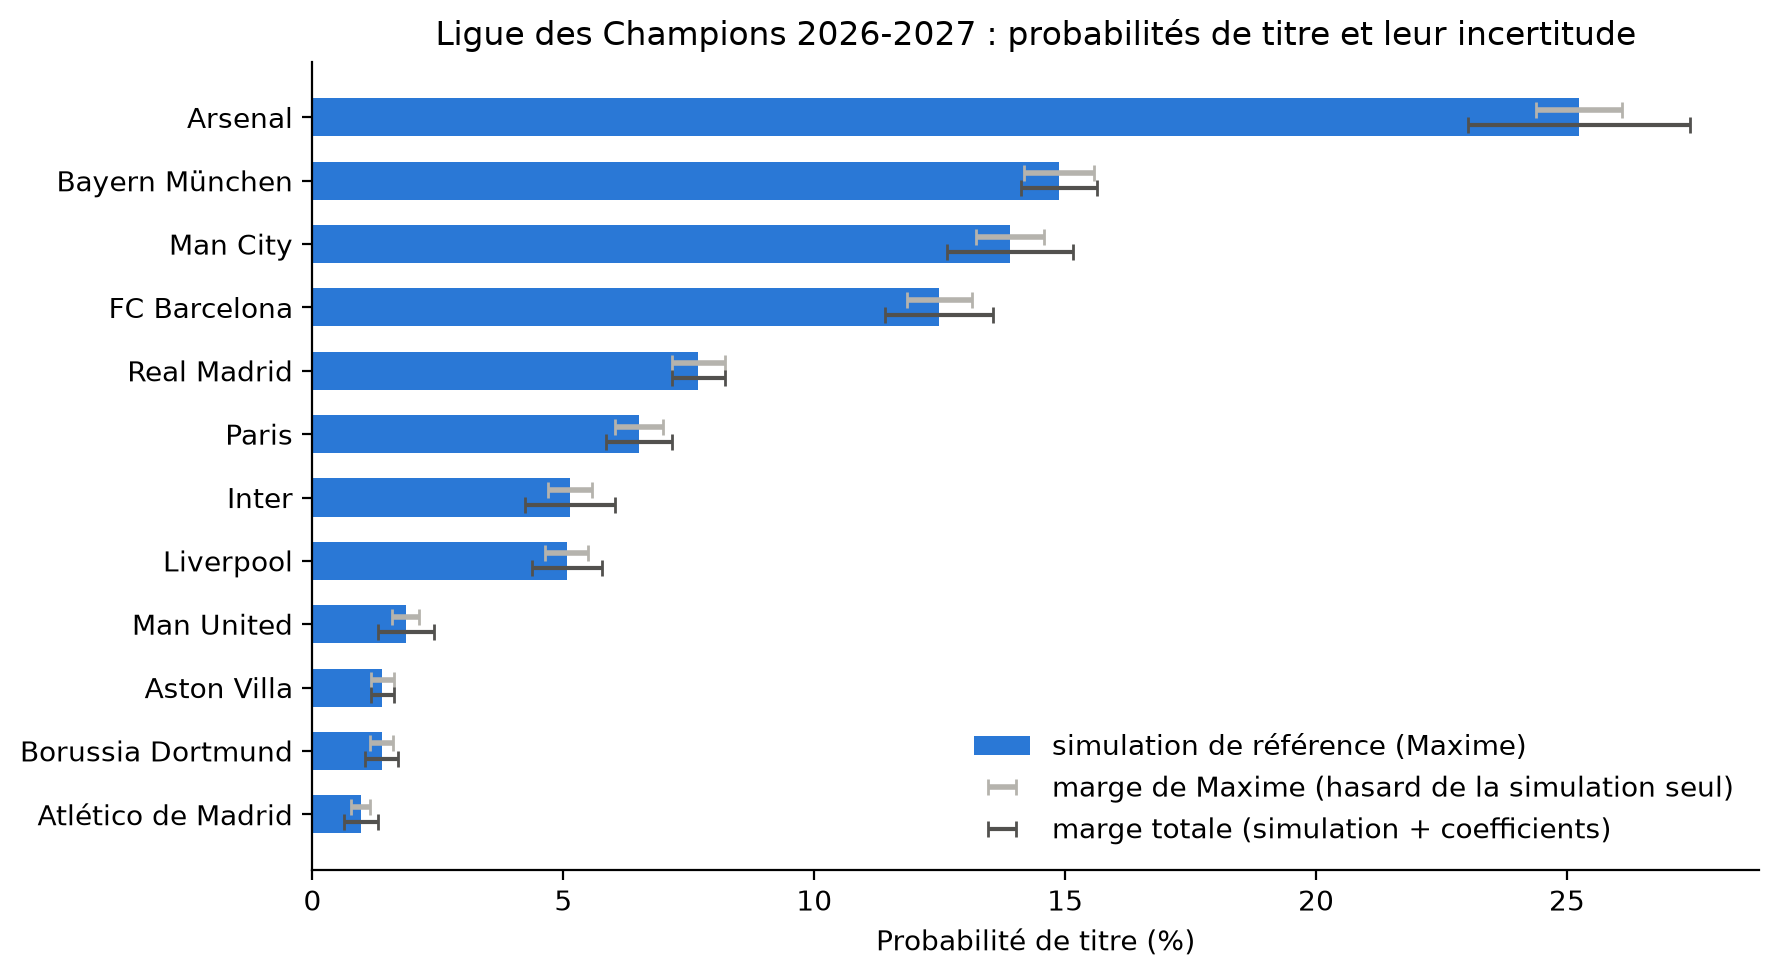

In [5]:
# Graphique : probabilité de titre des 12 favoris, avec la fourchette due au modèle
top = incertitude.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y, top['pct_titre_reference'], color=BLEU, height=0.6, label='simulation de référence (Maxime)')
ax.errorbar(top['pct_titre_reference'], y + 0.12, xerr=top['marge_titre_simulation_pts'], fmt='none', ecolor=GRIS,
            elinewidth=2, capsize=3, label='marge de Maxime (hasard de la simulation seul)')
ax.errorbar(top['pct_titre_reference'], y - 0.12, xerr=top['marge_titre_totale_pts'], fmt='none', ecolor=ENCRE,
            elinewidth=1.5, capsize=3, label='marge totale (simulation + coefficients)')
ax.set_yticks(y, top['nom_uefa'])
ax.set_xlabel('Probabilité de titre (%)')
ax.set_title('Ligue des Champions 2026-2027 : probabilités de titre et leur incertitude')
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**

| Club | Titre (Maxime) | Marge de Maxime | Marge due aux coefficients | **Marge totale** | **Fourchette à 95 %** |
|---|---|---|---|---|---|
| Arsenal | 25,24 % | ± 0,85 | ± 2,04 | **± 2,21** | **23,0 à 27,5 %** |
| Bayern | 14,87 % | ± 0,70 | ± 0,30 | **± 0,76** | **14,1 à 15,6 %** |
| Man City | 13,90 % | ± 0,68 | ± 1,05 | **± 1,25** | **12,6 à 15,2 %** |
| Barcelone | 12,49 % | ± 0,65 | ± 0,85 | **± 1,07** | **11,4 à 13,6 %** |
| Real Madrid | 7,69 % | ± 0,52 | ± 0,06 | **± 0,53** | **7,2 à 8,2 %** |

- **Pour le favori, la vraie marge est plus de deux fois plus grande** que celle annoncée : **± 2,2 points** au lieu de ± 0,85 pour Arsenal. C'est le club le plus sensible aux coefficients : il a à la fois le plus haut Elo et les meilleures forces, donc tout ce qui change le poids du niveau des clubs le fait bouger.
- **Pour les autres favoris, l'incertitude des coefficients est plus faible**, souvent du même ordre que le hasard de la simulation, voire trop petite pour être détectée (Real Madrid).
- **Pour atteindre les quarts, les coefficients pèsent bien plus que le hasard** : ± 2,9 points pour Arsenal (78,8 %), ± 3,1 pour Bayern (70,9 %), ± 2,6 pour Man City (66,6 %), contre environ ± 0,9 de hasard de simulation. L'incertitude du modèle domine.
- **Arsenal est clairement devant** : sa fourchette (23,0-27,5 %) ne touche pas celles des autres. **La 2e place n'est pas tranchée** : les fourchettes de Bayern (14,1-15,6 %) et de Man City (12,6-15,2 %) se chevauchent.
- **Ce que la marge ne couvre PAS :** elle ne tient compte que des coefficients. Les erreurs de l'Elo de départ et des forces, les limites du modèle en élimination directe (`AUDIT_MODELE`) et les règles simplifiées s'y ajoutent. **La vraie incertitude est donc plus grande encore** : ces fourchettes sont un minimum.
- **Une précision de méthode :** avec 100 tirages, la part due aux coefficients n'est qu'un ordre de grandeur. « Non détectable » signifie qu'elle est plus petite que le bruit de nos blocs, pas qu'elle est nulle.

## 4. Analyse de sensibilité : terrain, Elo, forces et valeur des joueurs

**La question :** les conclusions tiennent-elles si un coefficient est un peu différent ? On change **un seul coefficient à la fois** et on relance 10 000 saisons, **avec la même graine** pour chaque scénario : les différences viennent alors du coefficient changé, pas du hasard.

**Les scénarios, fixés avant de lancer :**
- **terrain** : bornes basse et haute de son intervalle de confiance, puis **aucun avantage du terrain** (cas extrême) ;
- **poids de l'Elo** : bornes de son intervalle de confiance, puis **−25 % et +25 %** (test de résistance, bien au-delà de l'intervalle) ;
- **nouveau format retiré** : l'audit a montré que son gain n'est pas démontré, on regarde donc ce qui change sans lui ;
- **forces d'attaque/défense** : bornes de leur intervalle de confiance ;
- **valeur des joueurs récents retirée** : la variable la plus récente du modèle, on regarde ce qu'elle change.

Les trois derniers scénarios ont été ajoutés avec le modèle v3, avant de lancer les calculs.

On regarde : le top 3 change-t-il ? Le classement des 36 clubs (corrélation de Spearman avec la référence) ? Et la probabilité de titre du favori ?

In [6]:
ic = dict(zip(COEFS, zip(ajust.conf_int()[0], ajust.conf_int()[1])))
scenarios = {
    'référence': {},
    'terrain : borne basse de l\'IC': {'coef_terrain': ic['coef_terrain'][0]},
    'terrain : borne haute de l\'IC': {'coef_terrain': ic['coef_terrain'][1]},
    'terrain : aucun avantage': {'coef_terrain': 0.0},
    'Elo : borne basse de l\'IC': {'coef_ecart_100': ic['coef_ecart_100'][0]},
    'Elo : borne haute de l\'IC': {'coef_ecart_100': ic['coef_ecart_100'][1]},
    'Elo : −25 % (stress)': {'coef_ecart_100': 0.75 * p['coef_ecart_100']},
    'Elo : +25 % (stress)': {'coef_ecart_100': 1.25 * p['coef_ecart_100']},
    'sans le nouveau format': {'coef_nouveau_format': 0.0},
    'forces : borne basse de l\'IC': {'coef_force_ad': ic['coef_force_ad'][0]},
    'forces : borne haute de l\'IC': {'coef_force_ad': ic['coef_force_ad'][1]},
    'sans la valeur des joueurs récents': {'coef_valeur_recente': 0.0},
}
debut = time.perf_counter()
# Même graine pour tous les scénarios : seules les différences de coefficient changent les résultats
sorties = Parallel(n_jobs=-1)(delayed(simuler_avec)(changement, N_SENSIBILITE, GRAINE) for changement in scenarios.values())
titres = pd.DataFrame({nom: 100 * s[0] for nom, s in zip(scenarios, sorties)}, index=clubs['nom_uefa'])
assert np.allclose(titres['référence'].to_numpy(), 100 * reference.set_index('nom_uefa').loc[titres.index, 'p_titre'].to_numpy())

ordre_ref = titres['référence'].sort_values(ascending=False).index
top3_ref = list(ordre_ref[:3])
sensibilite = pd.DataFrame({
    'top 3': [', '.join(titres[s].sort_values(ascending=False).index[:3]) for s in scenarios],
    'même top 3 (ordre compris)': [list(titres[s].sort_values(ascending=False).index[:3]) == top3_ref for s in scenarios],
    'même top 3 (ordre libre)': [set(titres[s].sort_values(ascending=False).index[:3]) == set(top3_ref) for s in scenarios],
    'Spearman avec la référence': [titres[s].corr(titres['référence'], method='spearman') for s in scenarios],
    f'titre {ordre_ref[0]} (%)': [titres.loc[ordre_ref[0], s] for s in scenarios],
    f'titre {ordre_ref[1]} (%)': [titres.loc[ordre_ref[1], s] for s in scenarios],
    f'titre {ordre_ref[2]} (%)': [titres.loc[ordre_ref[2], s] for s in scenarios],
}, index=list(scenarios))
print(f"{len(scenarios)} scénarios × {N_SENSIBILITE:,} saisons en {time.perf_counter() - debut:.0f} s\n")
print(sensibilite.round(3).to_string())

12 scénarios × 10,000 saisons en 16 s

                                                                    top 3  même top 3 (ordre compris)  même top 3 (ordre libre)  Spearman avec la référence  titre Arsenal (%)  titre Bayern München (%)  titre Man City (%)
référence                               Arsenal, Bayern München, Man City                        True                      True                       1.000              25.24                     14.87               13.90
terrain : borne basse de l'IC           Arsenal, Man City, Bayern München                       False                      True                       0.990              25.30                     14.11               14.91
terrain : borne haute de l'IC           Arsenal, Man City, Bayern München                       False                      True                       0.978              25.21                     14.20               14.58
terrain : aucun avantage                Arsenal, Bayern München, Man City    

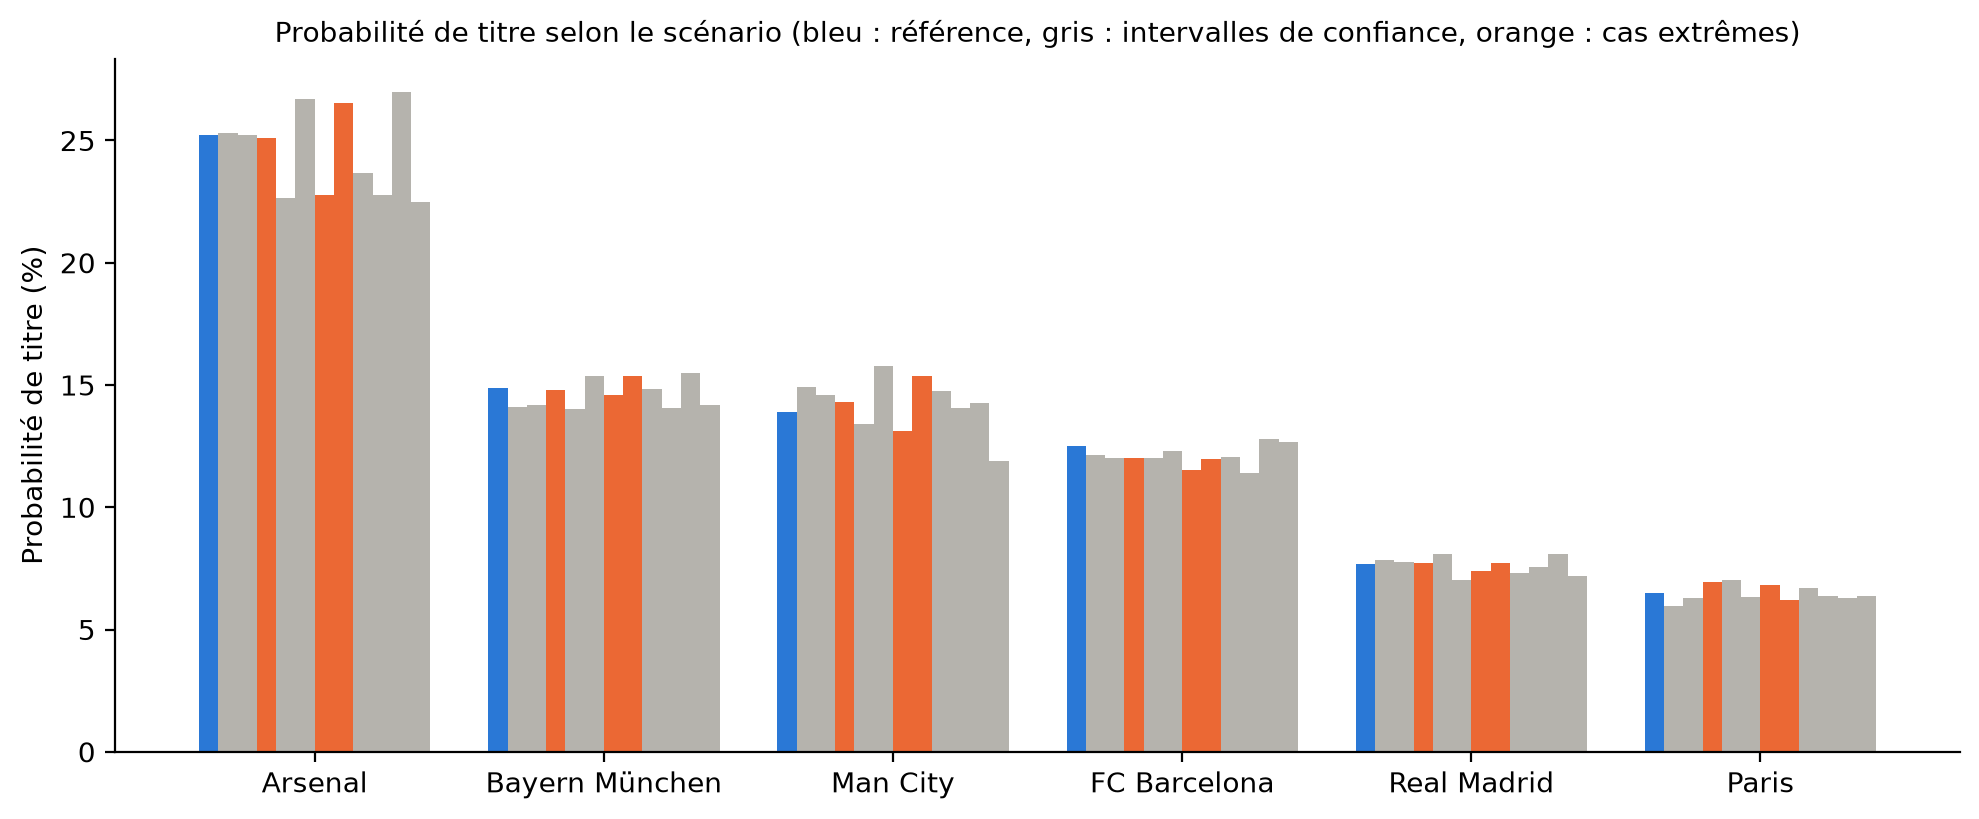

In [7]:
# Graphique : probabilité de titre des 6 favoris selon le scénario
favoris = list(ordre_ref[:6])
fig, ax = plt.subplots(figsize=(10, 4.2))
largeur = 0.8 / len(scenarios)
for i, s in enumerate(scenarios):
    couleur = BLEU if s == 'référence' else (ORANGE if 'stress' in s or 'aucun' in s else GRIS)
    ax.bar(np.arange(len(favoris)) + (i - (len(scenarios) - 1) / 2) * largeur, titres.loc[favoris, s], largeur, color=couleur)
ax.set_xticks(np.arange(len(favoris)), favoris)
ax.set_ylabel('Probabilité de titre (%)')
ax.set_title('Probabilité de titre selon le scénario (bleu : référence, gris : intervalles de confiance, orange : cas extrêmes)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**

| Scénario | Top 3 | Spearman | Arsenal | Bayern | Man City |
|---|---|---|---|---|---|
| **Référence** | Arsenal, Bayern, City | 1,000 | 25,2 % | 14,9 % | 13,9 % |
| Terrain : bornes de l'IC | Arsenal, City, Bayern | 0,978 à 0,990 | 25,2 à 25,3 % | 14,1 à 14,2 % | 14,6 à 14,9 % |
| Terrain : aucun avantage | identique | 0,992 | 25,1 % | 14,8 % | 14,3 % |
| Elo : bornes de l'IC | identique, ou City 2e | 0,987 à 0,991 | **22,7 à 26,7 %** | 14,0 à 15,4 % | 13,4 à 15,8 % |
| Elo : −25 % / +25 % (stress) | identique | 0,986 à 0,989 | 22,8 à 26,6 % | 14,6 à 15,4 % | 13,1 à 15,4 % |
| Sans le nouveau format | identique | 0,996 | 23,7 % | 14,8 % | 14,7 % |
| Forces : bornes de l'IC | identique | 0,986 à 0,997 | **22,8 à 27,0 %** | 14,1 à 15,5 % | 14,0 à 14,3 % |
| Sans la valeur des joueurs récents | Arsenal, Bayern, **Barcelone** | 0,981 | 22,5 % | 14,2 % | 11,9 % |

- **Arsenal reste 1er dans les 12 scénarios.** Le classement des 36 clubs reste presque identique (Spearman toujours ≥ 0,978).
- **Bayern et Man City s'échangent la 2e place** dans 3 scénarios. Leur écart (1 point) est du même ordre que le hasard de la simulation : il ne faut pas leur donner un ordre fixe.
- **Le terrain compte très peu pour le titre** : même sans aucun avantage du terrain, Arsenal ne perd que 0,2 point. C'est logique : en phase de ligue, chaque club joue 4 matchs à domicile et 4 à l'extérieur, donc l'avantage s'équilibre.
- **Ce qui compte, c'est le poids du niveau des clubs** : l'Elo et les forces font chacun varier Arsenal d'environ 4 points dans leur intervalle de confiance (22,7 à 27,0 %). Plus le niveau pèse, plus les favoris sont favoris.
- **La valeur des joueurs récents aide surtout Man City** : sans elle, City tombe à 11,9 % et Barcelone passe 3e. C'est le seul scénario qui change la composition du top 3.
- **Retirer le nouveau format change peu** : Arsenal 23,7 % (−1,6 point), les autres presque rien.

## 5. Export

Deux fichiers dans `output/` (non versionnés, comme les autres sorties) :
- `incertitude_titre_2026.csv` : pour chaque club, la probabilité de titre de référence, sa fourchette à 95 % quand les coefficients sont incertains, et la même chose pour les quarts de finale ;
- `sensibilite_2026.csv` : la probabilité de titre de chaque club dans chacun des 12 scénarios.

In [8]:
assert len(incertitude) == 36 and incertitude['club_id'].is_unique
assert (incertitude['pct_titre_ic95_bas'] <= incertitude['pct_titre_ic95_haut']).all()
assert np.isclose(incertitude['pct_titre_moyen_coefs_incertains'].sum(), 100) and np.isclose(incertitude['pct_titre_reference'].sum(), 100)
assert np.allclose(titres.sum(), 100)

incertitude.to_csv('../output/incertitude_titre_2026.csv', index=False, encoding='utf-8-sig')
titres.reset_index().rename(columns={'nom_uefa': 'club'}).to_csv('../output/sensibilite_2026.csv', index=False, encoding='utf-8-sig')
print("Fichiers créés : output/incertitude_titre_2026.csv (36 lignes), output/sensibilite_2026.csv (36 lignes × 12 scénarios)")

Fichiers créés : output/incertitude_titre_2026.csv (36 lignes), output/sensibilite_2026.csv (36 lignes × 12 scénarios)


**Lecture :** les deux fichiers sont créés, 36 lignes chacun, avec des probabilités qui somment bien à 100 % dans chaque scénario.

## 6. Conclusion

**Ce que ce notebook apporte :**
1. **Des intervalles honnêtes.** La marge de ± 0,85 point annoncée pour Arsenal ne mesurait que le hasard de la simulation. En ajoutant l'incertitude des coefficients, elle passe à **± 2,2 points** : **23,0 à 27,5 %** de chances de titre. Pour atteindre les quarts, l'incertitude du modèle est même **environ 3 fois plus grande** que le hasard de la simulation pour les trois favoris.
2. **Un favori robuste.** Arsenal reste 1er dans **les 12** scénarios testés, y compris les cas extrêmes. En revanche, l'ordre entre Bayern et Man City n'est pas tranché.
3. **Ce qui compte vraiment : le poids du niveau des clubs** (Elo et forces), et dans une moindre mesure la valeur des joueurs récents. L'avantage du terrain et le nouveau format changent peu les conclusions.

**Ce qu'on peut dire en soutenance :** « Arsenal est le favori, avec environ 23 à 27 % de chances de titre, et il reste premier dans tous nos tests de sensibilité. Derrière, Bayern et Man City sont au coude à coude. Ces fourchettes ne couvrent que l'incertitude des coefficients : l'Elo de départ, les forces et les limites du modèle en élimination directe ajoutent une incertitude qu'on ne sait pas chiffrer. »

**Limites :**
- **L'incertitude de l'Elo de départ et des forces n'est pas prise en compte** : elles sont traitées comme exactes. Pour les clubs à Elo estimé, l'erreur moyenne est d'environ 43 points (`v2_elo`).
- **Le moteur est celui de Maxime**, avec ses règles simplifiées (départage final au hasard, retour chez le meilleur rang). On ne les a pas testées ici.
- **100 tirages de coefficients** suffisent pour un ordre de grandeur des marges, pas pour un chiffre précis au dixième de point.